<a href="https://colab.research.google.com/github/pratapsingh23/uk-road-accident-severity-prediction/blob/main/Severity_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# data loading
import pandas as pd

from data_loading import data_loading, files
df = data_loading(files['final_df'])

In [9]:
# required libary for model
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
df['month'] = df['date'].dt.month
df['hour'] = pd.to_datetime(
    df['time'], errors='coerce'
).dt.hour

/tmp/ipykernel_548/946519373.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['hour'] = pd.to_datetime(


In [14]:

cat_cols = [
    'day_of_week', 'urban_or_rural_area',  'road_type', 'light_conditions', 'weather_conditions',
    'trunk_road_flag',

]

num_cols =[
    'month', 'hour', 'latitude', 'longitude',
    'speed_limit', 'number_of_vehicles'
]


for col in cat_cols:
  df[col] = df[col].astype('category')

features = cat_cols + num_cols
target = 'collision_severity'

X = df[features].copy()
y = df[target].copy()


In [15]:
train_mask = df['year'] <= 2023
val_mask = df['year'] == 2024
test_mask = df['year'] == 2025

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_val = X.loc[val_mask].copy()
y_val = y.loc[val_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

In [16]:
class_weights = {
    1: 20,
    2: 3,
    3: 1
}

sample_weights = y_train.map(class_weights).to_numpy()

In [19]:
best_params = {
    'min_samples_leaf': 20,
    'max_leaf_nodes': 63,
    'max_iter': 200,
    'max_bins': 255,
    'learning_rate': 0.05,
    'l2_regularization': 5.0
}

In [24]:
# Model
validation_model = HistGradientBoostingClassifier(
    **best_params,
    categorical_features='from_dtype',
    early_stopping=False,
    random_state=42
)

validation_model.fit(
    X_train, y_train, sample_weight=sample_weights
)

def predict_severity(model, X_data, threshold=0.40):
  probablites = model.predict_proba(X_data)

  classes = model.classes_

  fatal_index = list(classes).index(1)
  fatal_probabilites = probablites[:, fatal_index]
  other_classes = classes[classes != 1]
  other_probabilites = probablites[:, classes != 1]

  predictions = other_classes[
      np.argmax(other_probabilites, axis=1)
  ]

  predictions[fatal_probabilites >= threshold] =1
  return predictions

In [25]:
y_val_pred = predict_severity(
    validation_model, X_val, threshold=0.40
)


print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred, average='macro'))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

Validation Accuracy: 0.6285533108088024
Validation Macro F1: 0.41027427188881593

Classification Report:

              precision    recall  f1-score   support

       Fatal       0.08      0.17      0.11      1502
     Serious       0.32      0.45      0.38     23567
      Slight       0.81      0.69      0.75     75858

    accuracy                           0.63    100927
   macro avg       0.40      0.44      0.41    100927
weighted avg       0.69      0.63      0.65    100927



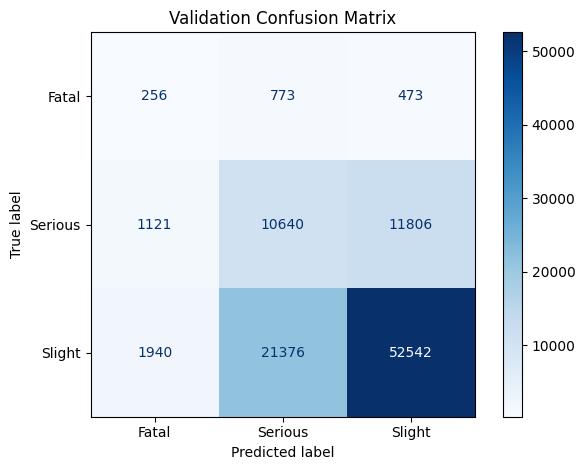

In [26]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fatal', 'Serious', 'Slight']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Validation Confusion Matrix')
plt.tight_layout()
plt.show()

In [28]:
# Final model training:
X_final_train = df.loc[df['year'] <= 2024, features].copy()

y_final_train = df.loc[df['year'] <= 2024, target].copy()

X_final_test = df.loc[
    df['year'] == 2025, features
].copy()

y_final_test = df.loc[
    df['year'] == 2025, target
].copy()

In [30]:
final_sample_weights = y_final_train.map(
    class_weights
).to_numpy()

In [31]:
final_model = HistGradientBoostingClassifier(
    **best_params,
    categorical_features='from_dtype',
    early_stopping=False,
    random_state=42

)

final_model.fit(
    X_final_train, y_final_train, sample_weight=final_sample_weights
)


HistGradientBoostingClassifier(early_stopping=False, l2_regularization=5.0,
                               learning_rate=0.05, max_iter=200,
                               max_leaf_nodes=63, random_state=42)

In [32]:
# Final testing on 2025 year's data:
y_test_pred = predict_severity(
    final_model,
    X_final_test,
    threshold=0.40
)

In [36]:
# Metrics:
print("Final Test Accuracy:",
      accuracy_score(y_final_test, y_test_pred))
print("Final Test Macro F1:", f1_score(y_final_test, y_test_pred, average='macro'))

print("\nFinal Classification Report\n")

print(classification_report(
    y_final_test,
    y_test_pred,
    labels=[1, 2, 3],
    target_names=['Fatal', 'Serious', 'Slight'],
    zero_division=0
))

Final Test Accuracy: 0.6122137404580152
Final Test Macro F1: 0.406541724586402

Final Classification Report

              precision    recall  f1-score   support

       Fatal       0.08      0.19      0.11      1453
     Serious       0.33      0.45      0.38     25191
      Slight       0.80      0.67      0.73     74881

    accuracy                           0.61    101525
   macro avg       0.40      0.44      0.41    101525
weighted avg       0.67      0.61      0.63    101525



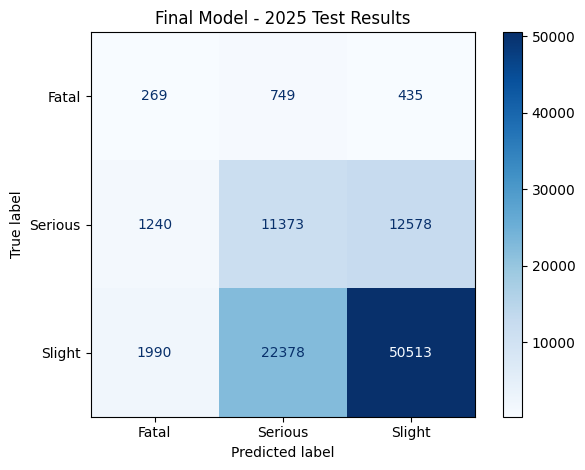

In [34]:
cm = confusion_matrix(
    y_final_test,
    y_test_pred,
    labels=[1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fatal', 'Serious', 'Slight']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Final Model - 2025 Test Results')
plt.tight_layout()
plt.show()

In [37]:
model_bundle = {
    'model': final_model,
    'features': features,
    'categorical_features': cat_cols,
    'threshold': 0.40,
    'class_labels': {
        1: 'Fatal',
        2: 'Serious',
        3: 'Slight'
    }
}

joblib.dump(
    model_bundle,
    'uk_road_severity_hgb.pkl'
)

print("Model saved successfully!")

Model saved successfully!
